# TP – MLP avec Keras sur le dataset Dry Bean 🫘

On reprend **toutes les étapes du TP Digits**, mais avec un nouveau dataset : **Dry Bean** (UCI, id 602).

**Le problème :** 13 611 haricots secs ont été photographiés. Pour chacun, on a mesuré **16 caractéristiques de forme** (surface, périmètre, longueurs, rondeur…). Le but est de prédire **sa variété** parmi **7** : BARBUNYA, BOMBAY, CALI, DERMASON, HOROZ, SEKER, SIRA.

| | Digits | **Dry Bean** |
|---|---|---|
| Observations | 1 797 images | **13 611 haricots** |
| Entrées | 64 pixels (0 à 16) | **16 mesures**, d'échelles très différentes |
| Classes | 10 chiffres (des nombres) | **7 variétés** (des **mots**) |
| Équilibre | ~180 par classe | **déséquilibré** (522 à 3 546) |

**Méthode :** exécuter les cellules **dans l'ordre** avec **Maj + Entrée**. Après chaque cellule de code, une cellule 📘 explique ce qu'elle fait et ce qu'il faut voir.

## Étape 1 – Installer le package `ucimlrepo`

In [5]:
%pip install ucimlrepo pandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


📘 **Explication**

- `ucimlrepo` est un petit package qui **télécharge les datasets du site UCI** directement dans Python.
- On écrit **`%pip`** (avec `%`) plutôt que `!pip` : `%pip` installe dans **le même Python que Jupyter** (ici Python 3.12, celui qui a TensorFlow).
- **À voir :** `Successfully installed ucimlrepo…` ou `Requirement already satisfied`. Si c'est la première installation, il peut être utile de **redémarrer le kernel** (menu *Kernel → Restart Kernel*).

## Étape 2 – Importer les outils

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (accuracy_score, f1_score, recall_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)
from ucimlrepo import fetch_ucirepo

SEED = 42
keras.utils.set_random_seed(SEED)
print("TensorFlow :", tf.__version__, "| Keras :", keras.__version__)
plt.rcParams.update({"figure.figsize": (7, 4), "font.size": 11})

TensorFlow : 2.21.0 | Keras : 3.15.1


 **Explication**

| Outil | À quoi il sert |
|---|---|
| `numpy`, `matplotlib` | calculs et graphiques (comme avant) |
| **`pandas`** (nouveau) | manipuler des **tableaux de données** (DataFrame) avec des noms de colonnes |
| `tensorflow`, `keras`, `layers` | construire et entraîner le réseau de neurones |
| `train_test_split`, `StandardScaler` | séparer et standardiser (comme avant) |
| **`LabelEncoder`** (nouveau) | transformer les **noms** des variétés en **nombres** 0, 1, 2… |
| `accuracy_score`, `f1_score`, **`recall_score`**… | mesurer les performances |
| **`fetch_ucirepo`** (nouveau) | télécharger le dataset |

`SEED = 42` fixe le hasard pour obtenir les **mêmes résultats** à chaque exécution.




## Étape 3 – Charger le dataset Dry Bean

In [7]:
dry_bean = fetch_ucirepo(id=602)

X_df = dry_bean.data.features
y_text = dry_bean.data.targets.values.ravel()

print("X :", X_df.shape, "| y :", y_text.shape)
print("Les 16 mesures :", list(X_df.columns))
print("Exemples de classes :", y_text[:5])
X_df.head()

X : (13611, 16) | y : (13611,)
Les 16 mesures : ['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRatio', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'Roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4']
Exemples de classes : ['SEKER' 'SEKER' 'SEKER' 'SEKER' 'SEKER']


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166


**Explication**

| Ligne | Sens |
|---|---|
| `fetch_ucirepo(id=602)` | télécharge le dataset **n° 602** de l'UCI (il faut internet) |
| `dry_bean.data.features` | le tableau des **16 mesures** → les **entrées X** |
| `dry_bean.data.targets` | la colonne `Class` → la **cible y** (la variété) |
| `.values.ravel()` | transforme cette colonne en **simple liste** de 13 611 noms |
| `X_df.head()` | affiche les **5 premières lignes** |



 **Ce qu'il faut remarquer :**
- les classes sont des **mots**, pas des nombres → il faudra un **LabelEncoder** ;
- `Area` vaut des **dizaines de milliers**, alors que `Eccentricity` est **entre 0 et 1** → les **échelles sont très différentes** : le **StandardScaler** sera indispensable.

## Étape 4 – Analyser les données

**Q1.** Nombre d'observations et de variables ? Que représente une ligne de X ? Régression ou classification ?

Types des colonnes :
float64    14
int64       2
str         1
Name: count, dtype: int64

Valeurs manquantes : 0

Minimum et maximum de chaque mesure :
                       min         max
Area             20420.000  254616.000
Perimeter          524.736    1985.370
MajorAxisLength    183.601     738.860
MinorAxisLength    122.513     460.198
AspectRatio          1.025       2.430
Eccentricity         0.219       0.911
ConvexArea       20684.000  263261.000
EquivDiameter      161.244     569.374
Extent               0.555       0.866
Solidity             0.919       0.995
Roundness            0.490       0.991
Compactness          0.641       0.987
ShapeFactor1         0.003       0.010
ShapeFactor2         0.001       0.004
ShapeFactor3         0.410       0.975
ShapeFactor4         0.948       1.000

Effectif de chaque variété :
Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64


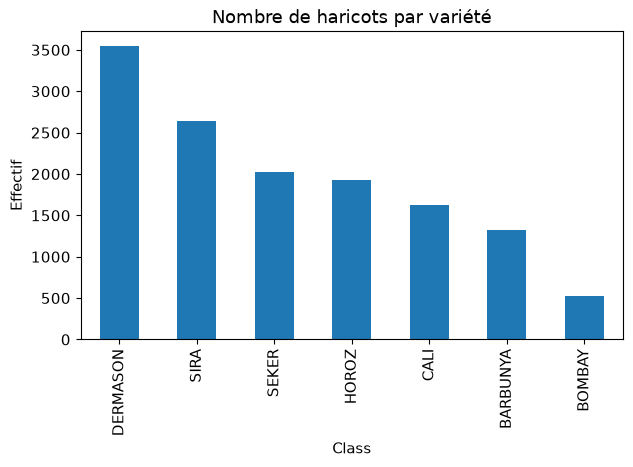

Doublons exacts : 68
Après suppression des doublons : (13543, 17)


In [8]:
bean = X_df.copy()
bean["Class"] = y_text

print("Types des colonnes :")
print(bean.dtypes.value_counts())
print("\nValeurs manquantes :", bean.isna().sum().sum())

print("\nMinimum et maximum de chaque mesure :")
print(X_df.describe().loc[["min", "max"]].T.round(3))

print("\nEffectif de chaque variété :")
counts = bean["Class"].value_counts()
print(counts)
counts.plot(kind="bar", title="Nombre de haricots par variété")
plt.ylabel("Effectif")
plt.show()

print("Doublons exacts :", bean.duplicated().sum())
bean = bean.drop_duplicates().reset_index(drop=True)
print("Après suppression des doublons :", bean.shape)

**Explication**

| Partie | Sens |
|---|---|
| `bean = X_df.copy()` puis `bean["Class"] = y_text` | on met les **mesures et la variété dans un même tableau**, pour supprimer les doublons sur la ligne complète |
| `dtypes.value_counts()` | le **type** des colonnes (nombres à virgule `float64`, entiers `int64`, texte `object`) |
| `isna().sum().sum()` | le nombre de **cases vides** |
| `describe().loc[["min","max"]]` | le **minimum et le maximum** de chaque mesure → on voit les échelles |
| `value_counts()` + graphique | **combien de haricots** par variété |
| `duplicated()` / `drop_duplicates()` | compte puis **supprime les lignes en double**, **avant** la séparation (sinon un même haricot pourrait être dans le train **et** le test = triche) |



**Réponse Q1 :** une ligne de X = **un haricot** décrit par 16 mesures. C'est une **classification** (7 variétés), car la variété est une **étiquette** : il n'y a ni ordre ni distance entre « SIRA » et « BOMBAY ».

## Étape 5 – Transformer les noms des variétés en nombres (`LabelEncoder`)

In [9]:
X = bean.drop(columns="Class").values.astype("float32")
encoder = LabelEncoder()
y = encoder.fit_transform(bean["Class"].values)

class_names = list(encoder.classes_)
n_inputs = X.shape[1]
n_classes = len(class_names)
print("Correspondance indice -> variété :", dict(enumerate(class_names)))
print("Entrées :", n_inputs, "| Classes :", n_classes)
print("Exemple : y[:5] =", y[:5])

Correspondance indice -> variété : {0: 'BARBUNYA', 1: 'BOMBAY', 2: 'CALI', 3: 'DERMASON', 4: 'HOROZ', 5: 'SEKER', 6: 'SIRA'}
Entrées : 16 | Classes : 7
Exemple : y[:5] = [5 5 5 5 5]


 **Explication – nouvelle notion : `LabelEncoder`**

Keras (avec `SparseCategoricalCrossentropy`) veut des classes sous forme de **nombres entiers consécutifs commençant à 0**. Or nos classes sont des **mots**.

| Ligne | Sens |
|---|---|
| `bean.drop(columns="Class")` | les **entrées** : toutes les colonnes **sauf** la variété |
| `.values.astype("float32")` | transforme le tableau pandas en **tableau numpy** de nombres (ce que Keras attend) |
| `encoder.fit_transform(...)` | **apprend** la liste des 7 noms (par ordre alphabétique) et les remplace par **0 à 6** |
| `encoder.classes_` | la **correspondance** : l'indice 0 = BARBUNYA, 1 = BOMBAY, … |



 Il faut **garder cet encodeur** : à la fin, il sert à retrouver le **nom** de la variété à partir du nombre prédit (`encoder.inverse_transform`).

## Étape 6 – Séparer (60/20/20) et standardiser

**Q2.** Pourquoi conserver les proportions des classes ? Pourquoi ne pas ajuster le scaler sur toutes les données ? Différence validation / test ?

In [10]:
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.25, random_state=SEED, stratify=y_dev)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

print("Train / validation / test :", len(y_train), len(y_val), len(y_test))
print("Effectifs train par classe :", np.bincount(y_train))
print("Area avant  : moyenne =", round(X_train[:, 0].mean()), "| écart-type =", round(X_train[:, 0].std()))
print("Area après  : moyenne =", round(X_train_s[:, 0].mean(), 3), "| écart-type =", round(X_train_s[:, 0].std(), 3))
assert np.allclose(scaler.mean_, X_train.mean(axis=0), rtol=1e-4)

Train / validation / test : 8125 2709 2709
Effectifs train par classe : [ 793  313  978 2127 1116 1216 1582]
Area avant  : moyenne = 53035 | écart-type = 29367
Area après  : moyenne = -0.0 | écart-type = 1.0


 **Explication** (comme dans Digits)

- 1er `train_test_split` → **20 %** pour le **test** ; 2e → **25 % du reste** (= 20 %) pour la **validation** ; il reste **60 %** pour le **train**.
- `stratify` garde **la même proportion de chaque variété** dans les 3 ensembles (important ici car BOMBAY est rare).
- Le scaler est **ajusté sur le train seulement** (`fit_transform`), puis **appliqué** aux deux autres (`transform`) → **pas de fuite de données**.

**À voir :** environ `8125 2709 2709`, et pour `Area` : avant, une moyenne d'environ **53 000** ; après, **0** et un écart-type de **1**.

 **Pourquoi c'est encore plus important qu'avec Digits ?** Sans standardisation, `Area` (≈ 50 000) **écraserait** complètement `Eccentricity` (≈ 0,7) dans la somme pondérée : le réseau apprendrait très mal. Après le scaler, les 16 mesures ont **la même échelle**.

**Réponse Q2 :** la stratification garde les classes rares dans chaque ensemble ; ajuster le scaler sur tout serait une **fuite** (on utiliserait des infos de la validation et du test) ; la **validation** sert à **choisir** les réglages, le **test** à mesurer la note finale **une seule fois**.

## Étape 7 – Construire le MLP 16 → 32 → 7

**Q3.** Combien de couches cachées ? Pourquoi 7 sorties ? Combien de paramètres ?

In [11]:
model = keras.Sequential([
    keras.Input(shape=(n_inputs,)),
    layers.Dense(32, activation="relu"),
    layers.Dense(n_classes, activation="softmax")
])
model.summary()
print("Paramètres :", model.count_params())
assert model.count_params() == 16*32 + 32 + 32*7 + 7

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 32)                  │             544 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 7)                   │             231 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 775 (3.03 KB)

 Trainable params: 775 (3.03 KB)

 Non-trainable params: 0 (0.00 B)

Paramètres : 775


 **Explication**

| Ligne | Sens |
|---|---|
| `keras.Input(shape=(n_inputs,))` | chaque haricot arrive sous forme de **16 nombres** (au lieu de 64 pixels) |
| `Dense(32, activation="relu")` | **1 couche cachée** de 32 neurones, chacun relié aux 16 entrées |
| `Dense(n_classes, activation="softmax")` | **7 sorties** = **une probabilité par variété** ; softmax fait que les 7 probabilités **somment à 1** |

**Le calcul des paramètres (poids + biais) :**

| Couche | Calcul | Paramètres |
|---|---|---|
| cachée | 16 × 32 + 32 biais | **544** |
| sortie | 32 × 7 + 7 biais | **231** |
| **total** | | **775** |

**Réponse Q3 :** 1 couche cachée ; 7 sorties car 7 variétés ; **775** paramètres (moins que les 2 410 de Digits, car seulement 16 entrées et 7 sorties).

## Étape 8 – Configurer l'apprentissage avec `compile`

**Q4.** Différence entre perte et accuracy ? Quelle sortie/perte pour une classification binaire ? Pour une régression ?

In [ ]:
model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
              loss=keras.losses.SparseCategoricalCrossentropy(),
              metrics=["accuracy"])
print("Modèle compilé.")

 **Explication – la fonction de perte**

On garde **`SparseCategoricalCrossentropy`** (entropie croisée catégorielle « sparse ») car :
- il y a **plusieurs classes** (7) → entropie croisée **catégorielle** ;
- nos cibles sont des **entiers** (0 à 6, grâce au LabelEncoder) → version **« sparse »**.

**Quelle perte choisir selon le problème ? (à connaître)**

| Problème | Couche de sortie | Perte Keras |
|---|---|---|
| **Multi-classe, cibles entières** (notre cas) | `Dense(7, softmax)` | `SparseCategoricalCrossentropy` |
| Multi-classe, cibles **one-hot** ([0,0,1,0,0,0,0]) | `Dense(7, softmax)` | `CategoricalCrossentropy` |
| **Binaire** (2 classes, comme le TP 1) | `Dense(1, sigmoid)` | `BinaryCrossentropy` |
| **Régression** (prédire un nombre) | `Dense(1)` sans activation | `MeanSquaredError` (MSE) |

- **Adam** (taux 0,001) : l'optimiseur qui corrige les poids.
- **accuracy** : le % de bonnes réponses, affiché pour **suivre** les progrès.

**Réponse Q4 :** la **perte** est ce que l'optimiseur **minimise** (elle tient compte de la confiance des probabilités) ; l'**accuracy** compte seulement les bonnes réponses. Binaire → sigmoïde + BinaryCrossentropy ; régression → sortie linéaire + MSE.

## Étape 9 – Entraîner avec `fit`

**Q5.** Que représentent `epochs`, `batch_size`, `validation_data` ? Combien de lots par époque ?

In [ ]:
history = model.fit(X_train_s, y_train,
                    validation_data=(X_val_s, y_val),
                    epochs=40, batch_size=32, verbose=0)
print("Courbes disponibles :", list(history.history))
print("Époques exécutées :", len(history.history["loss"]))
print("Lots par époque :", int(np.ceil(len(y_train) / 32)))

**Explication**

`fit` fait **automatiquement** la boucle du TP 1 : prédire → perte → gradients (rétropropagation) → mise à jour des poids.

| Réglage | Sens |
|---|---|
| `epochs=40` | **40 passages** sur tout le train |
| `batch_size=32` | les poids sont corrigés **toutes les 32 observations** |
| `validation_data` | la validation est **mesurée** à chaque époque, **jamais utilisée** pour corriger les poids |

**À voir :** `Époques exécutées : 40` et environ **254 lots par époque** (8 125 ÷ 32, arrondi au-dessus) → environ **10 000 mises à jour** au total. Ça prend un peu plus de temps que Digits (7 fois plus de données).

**Réponse Q5 :** voir le tableau ; environ 254 lots par époque ; **non**, les poids ne s'ajustent **pas** sur la validation.

## Étape 10 – Lire les courbes d'apprentissage

**Q6.** La perte diminue-t-elle ? Un écart train/validation apparaît-il ?

In [ ]:
def plot_history(history, title):
    h = history.history
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    axes[0].plot(h["loss"], label="Train")
    axes[0].plot(h["val_loss"], label="Validation")
    axes[0].set(xlabel="Époque", ylabel="Perte")
    axes[1].plot(h["accuracy"], label="Train")
    axes[1].plot(h["val_accuracy"], label="Validation")
    axes[1].set(xlabel="Époque", ylabel="Accuracy", ylim=(0, 1.05))
    for ax in axes:
        ax.legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

plot_history(history, "Premier MLP Dry Bean")

**Explication**

- **À gauche (perte)** : elle doit **descendre** vite puis se **stabiliser**.
- **À droite (accuracy)** : elle doit **monter** puis se stabiliser autour de **0,92–0,93**.
- Train et validation doivent rester **proches** : si la validation **remontait** pendant que le train baisse, ce serait du **sur-apprentissage**.

Avec Dry Bean, l'accuracy plafonne vers **92-93 %** (contre ~97 % pour Digits) : certaines variétés (SIRA, DERMASON) ont des formes **très proches** et sont difficiles à séparer.

## Étape 11 – Évaluer et prédire sur la validation

**Q7.** Forme du tableau de probabilités ? Pourquoi argmax ? Interpréter une confusion, la précision et le rappel d'une classe.

In [ ]:
val_scores = model.evaluate(X_val_s, y_val, verbose=0, return_dict=True)
prob_val = model.predict(X_val_s, verbose=0)
pred_val = np.argmax(prob_val, axis=1)

print("Évaluation :", val_scores)
print("Probabilités :", prob_val.shape)
assert np.allclose(prob_val.sum(axis=1), 1, atol=1e-5)
print(classification_report(y_val, pred_val, target_names=class_names, digits=3))

cm_val = confusion_matrix(y_val, pred_val, labels=np.arange(n_classes))
ConfusionMatrixDisplay(cm_val, display_labels=class_names).plot(cmap="Blues", xticks_rotation=45)
plt.title("Validation : lignes réelles, colonnes prédites")
plt.show()

 **Explication**

| Ligne | Sens |
|---|---|
| `evaluate(...)` | la **perte** et l'**accuracy** sur la validation |
| `predict(...)` | pour chaque haricot, **7 probabilités** → tableau de forme **(≈2709, 7)** |
| `np.argmax(..., axis=1)` | prend la **variété la plus probable** |
| `target_names=class_names` | **nouveau :** le rapport affiche les **noms** des variétés au lieu de 0 à 6 |
| `xticks_rotation=45` | penche les noms sous la matrice pour qu'ils soient lisibles |

**À voir :** une accuracy d'environ **0,92**. Dans le rapport :
- **BOMBAY** ≈ **1,000** partout : sa forme (très gros haricot) est **unique**, il n'y a aucune confusion malgré son petit effectif ;
- **SIRA** et **DERMASON** ont les scores les plus bas : la matrice montre qu'ils sont **souvent confondus** entre eux.

**Réponse Q7 :** forme (nombre d'images de validation, 7) ; argmax car avec 7 classes aucune probabilité ne dépasse forcément 0,5 ; la **précision** d'une variété = quand le réseau la prédit, a-t-il raison ? Le **rappel** = parmi les vrais haricots de cette variété, combien a-t-il trouvés ?

## Étape 12 – Une « usine à modèles » pour comparer les réglages

In [ ]:
def create_model(hidden=(32,), activation="relu", rate=0.001,
                 optimizer="adam", penalty=None, dropout=0.0, batchnorm=False,
                 input_dim=n_inputs, n_classes=n_classes):
    keras.utils.set_random_seed(SEED)
    net = keras.Sequential([keras.Input(shape=(input_dim,))])
    for units in hidden:
        net.add(layers.Dense(units, kernel_regularizer=penalty))
        if batchnorm:
            net.add(layers.BatchNormalization())
        net.add(layers.Activation(activation))
        if dropout > 0:
            net.add(layers.Dropout(dropout))
    net.add(layers.Dense(n_classes, activation="softmax"))
    opt = (keras.optimizers.Adam(learning_rate=rate) if optimizer == "adam"
           else keras.optimizers.SGD(learning_rate=rate))
    net.compile(optimizer=opt, loss="sparse_categorical_crossentropy",
                metrics=["accuracy"])
    return net

validation_loss = keras.losses.SparseCategoricalCrossentropy()
def summarize(name, net, hist):
    proba = net.predict(X_val_s, verbose=0)
    pred = proba.argmax(axis=1)
    return {"modèle": name, "paramètres": net.count_params(),
            "époques": len(hist.history["loss"]),
            "CE_validation": round(float(validation_loss(y_val, proba).numpy()), 4),
            "accuracy_validation": round(accuracy_score(y_val, pred), 4),
            "F1_macro_validation": round(f1_score(y_val, pred, average="macro"), 4)}
print("Fonctions prêtes.")

 **Explication**

C'est la même fonction que dans le TP Digits, avec **une seule différence** : `input_dim=n_inputs` (**16**) et `n_classes=n_classes` (**7**) au lieu de 64 et 10.

- `create_model(...)` fabrique un **réseau neuf** en changeant **un seul réglage** à la fois → comparaison **juste**.
- `summarize(...)` donne un résumé sur la validation : paramètres, époques, **CE** (entropie croisée), accuracy et **F1 macro**.
- **F1 macro** = la moyenne des F1 des 7 variétés, **chacune comptant autant**. C'est plus juste que l'accuracy quand les classes sont **déséquilibrées** (BOMBAY compte autant que DERMASON).

## Étape 13 – Comparer les taux d'apprentissage

**Q8.** Quel taux avance lentement ? Le grand taux est-il instable ?

In [ ]:
rate_runs = {}
for eta in [0.0001, 0.001, 0.05]:
    net = create_model(rate=eta)
    hist = net.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                   epochs=30, batch_size=32, verbose=0)
    rate_runs[eta] = (net, hist)
    print(summarize(f"Adam, taux={eta}", net, hist))
    plt.plot(hist.history["val_loss"], label=f"taux={eta}")
plt.xlabel("Époque")
plt.ylabel("Perte validation")
plt.legend()
plt.show()

 **Explication**

On entraîne **3 réseaux neufs** qui ne diffèrent que par le **taux d'apprentissage** (la taille des pas).

**Comment interpréter :**
- **0,0001** : pas trop petits → la perte descend **lentement**, le score est plus faible après 30 époques 🐌 ;
- **0,001** : en général le **bon compromis** ✅ ;
- **0,05** : pas grands → apprentissage rapide mais courbe de validation plus **irrégulière** ; il **ne diverge pas forcément** avec Adam.

**Pour Q8 :** comparer les courbes **et** les scores (CE et F1 macro) ; ne pas supposer qu'un grand taux diverge toujours.

## Étape 14 – Comparer les optimiseurs Adam et SGD

**Q9.** Quel appel Keras change ? Peut-on conclure qu'un optimiseur est toujours meilleur ?

In [ ]:
optimizer_runs = {}
for opt in ["adam", "sgd"]:
    net = create_model(rate=0.001, optimizer=opt)
    hist = net.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                   epochs=30, batch_size=32, verbose=0)
    optimizer_runs[opt] = (net, hist)
    print(summarize(opt, net, hist))

 **Explication**

- Seul l'**optimiseur** change : `keras.optimizers.Adam(...)` ou `keras.optimizers.SGD(...)`.
- **SGD** = la descente de gradient « simple » (comme le TP 1) ; **Adam** adapte la taille des pas pour chaque poids.
- Avec **le même taux 0,001**, SGD apprend en général **plus lentement**.

**Pour Q9 :** on ne peut **pas** conclure qu'Adam est toujours meilleur à partir d'un seul essai ; il faudrait **régler le taux de chaque optimiseur** séparément (par exemple 0,01 ou 0,1 pour SGD).

## Étape 15 – Comparer les tailles de lots

**Q10.** Combien de mises à jour par époque ? Pourquoi le même nombre d'époques ne veut pas dire le même nombre de mises à jour ?

In [ ]:
batch_runs = {}
for size in [1, 32, len(y_train)]:
    net = create_model(rate=0.01, optimizer="sgd")
    hist = net.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                   epochs=5, batch_size=size, verbose=0)
    batch_runs[size] = (net, hist)
    print(summarize(f"SGD, lot={size}", net, hist))
    print("Mises à jour par époque :", int(np.ceil(len(y_train) / size)))

 **Explication**

On compare **1 observation**, **32** et **tout le train** par lot, avec SGD (taux 0,01).

⚠️ J'ai mis **5 époques** (au lieu de 10 dans Digits) : avec **8 000 haricots**, le lot de 1 fait **8 000 mises à jour par époque**, ce qui est **long** sur un PC. Cette cellule peut prendre **1 à 3 minutes** : c'est normal.

| Lot | Mises à jour par époque |
|---|---|
| 1 | ≈ 8 125 |
| 32 | ≈ 254 |
| tout le train | **1** |

**Pour Q10 :** une époque = un passage sur toutes les données, mais le nombre de **corrections** = nombre de lots. Avec un lot complet, le réseau n'est corrigé que **5 fois** en 5 époques → il apprend très peu.

## Étape 16 – Comparer les architectures et activations

**Q11.** Comparer paramètres et scores. Un plus grand réseau généralise-t-il toujours mieux ?

In [12]:
architecture_runs = {}
for name, hidden, activation in [
        ("étroit", (2,), "relu"), ("référence", (32,), "relu"),
        ("deux couches", (64, 32), "relu"), ("tanh", (32,), "tanh")]:
    net = create_model(hidden=hidden, activation=activation)
    hist = net.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                   epochs=30, batch_size=32, verbose=0)
    architecture_runs[name] = (net, hist)
    print(summarize(name, net, hist))

NameError: name 'create_model' is not defined

 **Explication**

| Réseau | Couches cachées | Idée |
|---|---|---|
| étroit | 2 neurones | très petit : peut-il suffire ? |
| référence | 32 neurones ReLU | notre modèle de base |
| deux couches | 64 puis 32 | plus grand et plus profond |
| tanh | 32 neurones **tanh** | même taille, autre activation |

**Pour Q11 :** regarder si le gain de score **justifie** les paramètres en plus. Avec Dry Bean (16 mesures seulement), un réseau plus grand gagne en général **très peu** : plus grand **ne veut pas dire** toujours meilleur. Le réseau **étroit** (2 neurones) est trop petit pour bien séparer 7 classes.

## Étape 17 – Régulariser (L1, L2, Dropout, BatchNorm)

**Q12.** Comparer les CE sans pénalité. Pourquoi `evaluate` affiche une autre perte avec L1/L2 ?

In [ ]:
regularization_runs = {}
configs = [
    ("référence", {}),
    ("L1", {"penalty": keras.regularizers.l1(0.0001)}),
    ("L2", {"penalty": keras.regularizers.l2(0.001)}),
    ("Dropout", {"dropout": 0.25}),
    ("BatchNorm", {"batchnorm": True})
]
for name, options in configs:
    net = create_model(hidden=(64, 32), **options)
    hist = net.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                   epochs=35, batch_size=32, verbose=0)
    regularization_runs[name] = (net, hist)
    print(summarize(name, net, hist))
    print("   Perte evaluate (pénalité incluse) :",
          round(net.evaluate(X_val_s, y_val, verbose=0, return_dict=True)["loss"], 4))
plot_history(regularization_runs["Dropout"][1], "MLP Dry Bean avec Dropout")

 **Explication**

| Option | Ce qu'elle fait |
|---|---|
| **L1 / L2** | **punit les poids trop grands** (ajoute une pénalité à la perte) |
| **Dropout(0,25)** | **éteint au hasard 25 %** des neurones **pendant l'entraînement** |
| **BatchNorm** | **remet à l'échelle** les valeurs à l'intérieur du réseau |

- Pour comparer, on regarde **`CE_validation`** (calculée **sans** pénalité) : c'est un critère **commun**.
- Avec L1/L2, `evaluate` affiche une perte **plus grande**, car elle **ajoute la pénalité** des poids.
- Cette cellule est **longue** (5 réseaux × 35 époques) : patience ⏳.

**Pour Q12 :** aucune option n'améliore **systématiquement** le résultat ; il faut **tester** et comparer sur la validation.

## Étape 18 – Le Dropout n'agit que pendant l'entraînement

In [ ]:
probe = keras.Sequential([
    keras.Input(shape=(n_inputs,)), layers.Dense(16, activation="relu"),
    layers.Dropout(0.5), layers.Dense(n_classes, activation="softmax")
])
eval1 = probe(X_val_s[:8], training=False).numpy()
eval2 = probe(X_val_s[:8], training=False).numpy()
train1 = probe(X_val_s[:8], training=True).numpy()
train2 = probe(X_val_s[:8], training=True).numpy()
print("Évaluation identique :", np.allclose(eval1, eval2))
print("Entraînement identique :", np.allclose(train1, train2))

 **Explication**

- En mode **évaluation** (`training=False`, comme dans `predict` et `evaluate`), le Dropout est **éteint** → deux appels donnent **le même résultat** : `True`.
- En mode **entraînement** (`training=True`), il éteint des neurones **au hasard** → résultats **différents** : `False`.

👉 C'est pour ça qu'on utilise **`predict` / `evaluate`** pour les prédictions finales : les réponses sont **stables**.

## Étape 19 – Arrêt précoce avec `EarlyStopping`

**Q13.** Combien d'époques exécutées ? À quelle époque la meilleure perte de validation ? L'arrêt est-il garanti ?

In [ ]:
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=8,
                                           min_delta=0, restore_best_weights=True)
early_model = create_model()
early_history = early_model.fit(X_train_s, y_train,
                                validation_data=(X_val_s, y_val),
                                epochs=100, batch_size=32, verbose=0,
                                callbacks=[early_stop])
print("Époques exécutées :", len(early_history.history["loss"]))
print("Meilleure époque :", 1 + np.argmin(early_history.history["val_loss"]))
print(early_model.evaluate(X_val_s, y_val, verbose=0, return_dict=True))
plot_history(early_history, "Arrêt précoce et restauration des poids")

**Explication**

| Réglage | Sens |
|---|---|
| `monitor="val_loss"` | surveille la **perte de validation** |
| `patience=8` | arrête après **8 époques sans amélioration** |
| `restore_best_weights=True` | revient aux **poids de la meilleure époque** |
| `epochs=100` | c'est un **maximum** |

**Comment lire :** si par exemple « Époques exécutées : 40 » et « Meilleure époque : 32 », il s'est arrêté **8 époques après** la meilleure (32 + 8 = 40), puis il a repris les poids de l'époque 32.

**Pour Q13 :** l'arrêt n'est **pas garanti** avant 100 : si la perte de validation s'améliore encore un peu de temps en temps, il continue jusqu'au maximum.

## Étape 20 – Évaluation finale sur le test (une seule fois)

Le modèle est **choisi** (le modèle avec arrêt précoce). On ouvre **maintenant** le test, **une seule fois**, sans plus rien régler ensuite.

In [ ]:
prob_test = early_model.predict(X_test_s, verbose=0)
pred_test = prob_test.argmax(axis=1)

print("Accuracy test :", round(accuracy_score(y_test, pred_test), 4))
print("F1 macro test :", round(f1_score(y_test, pred_test, average="macro"), 4))
print(classification_report(y_test, pred_test, target_names=class_names, digits=3))

cm_test = confusion_matrix(y_test, pred_test, labels=np.arange(n_classes))
ConfusionMatrixDisplay(cm_test, display_labels=class_names).plot(cmap="Blues", xticks_rotation=45)
plt.title("Test : lignes réelles, colonnes prédites")
plt.show()

majority = np.bincount(y_train).argmax()
baseline = np.full_like(y_test, majority)
print("Baseline (toujours", class_names[majority], ") : accuracy =",
      round(accuracy_score(y_test, baseline), 4),
      "| F1 macro =", round(f1_score(y_test, baseline, average="macro"), 4))

wrong = np.where(pred_test != y_test)[0][:6]
print(pd.DataFrame({"variété réelle": encoder.inverse_transform(y_test[wrong]),
                    "variété prédite": encoder.inverse_transform(pred_test[wrong])}))

 **Explication**

| Partie | Sens |
|---|---|
| `predict` + `argmax` sur le **test** | la variété prédite pour chaque haricot jamais vu |
| `classification_report` / matrice | les scores **par variété**, avec les **vrais noms** |
| **baseline** | un modèle « bête » qui répond **toujours la variété la plus fréquente** du train (DERMASON) |
| `encoder.inverse_transform(...)` | **nouveau :** retransforme les nombres en **noms** de variétés |
| `wrong[:6]` | montre **6 haricots mal classés** |

**À voir :** une accuracy test d'environ **0,92-0,93**, et une baseline d'environ **0,26** (DERMASON ≈ 26 % des haricots), avec un F1 macro très faible (≈ 0,06). Notre réseau fait **beaucoup mieux**.

Les erreurs sont surtout **SIRA ↔ DERMASON** (et un peu BARBUNYA ↔ CALI) : ce sont des variétés aux **formes proches**.

## Étape 21 – Sauvegarder le modèle **et** les prétraitements

**Q14.** Pourquoi la sauvegarde du réseau seule ne suffit-elle pas ? Quelle transformation appliquer avant `predict` ?

In [ ]:
import joblib

early_model.save("modele_drybean.keras")
joblib.dump(scaler, "scaler_drybean.joblib")
joblib.dump(encoder, "encoder_drybean.joblib")

loaded_model = keras.models.load_model("modele_drybean.keras")
loaded_scaler = joblib.load("scaler_drybean.joblib")
loaded_encoder = joblib.load("encoder_drybean.joblib")

p_before = early_model.predict(X_val_s[:5], verbose=0)
p_after = loaded_model.predict(X_val_s[:5], verbose=0)
print("Prédictions conservées :", np.allclose(p_before, p_after, atol=1e-6))

nouveau_haricot = X_test[:1]
proba = loaded_model.predict(loaded_scaler.transform(nouveau_haricot), verbose=0)
print("Variété prédite pour un haricot brut :",
      loaded_encoder.inverse_transform(proba.argmax(axis=1))[0])

 **Explication**

Pour utiliser le modèle dans une **application**, il faut **3 fichiers** :

| Fichier | Contient | Pourquoi |
|---|---|---|
| `modele_drybean.keras` | le réseau (architecture + poids) | pour faire `predict` |
| `scaler_drybean.joblib` | la moyenne et l'écart-type **du train** | les **16 mesures brutes** doivent être standardisées **exactement comme pendant l'entraînement** |
| `encoder_drybean.joblib` | la correspondance 0 → BARBUNYA, … | pour retrouver le **nom** de la variété |

`joblib` est un outil qui **sauvegarde des objets Python** (ici le scaler et l'encodeur) dans un fichier.

**Le trajet d'un nouveau haricot :** mesures brutes → `scaler.transform` → `model.predict` → `argmax` → `encoder.inverse_transform` → **nom de la variété**.

**À voir :** `Prédictions conservées : True` et une variété prédite (par exemple `SIRA`).

**Réponse Q14 :** le fichier `.keras` ne contient **ni** le scaler **ni** l'encodeur ; sans eux, on ne peut pas transformer les mesures brutes ni lire le nom de la classe. Avant `predict`, appliquer **le même scaler** (`transform`, jamais un nouveau `fit`). `predict` **utilise** le modèle sans changer les poids ; `fit` **entraîne** le modèle.

## Résumé du processus et conclusion

### 1. Chargement des données
Le dataset Dry Bean (UCI, id 602) contient **13 611 haricots** décrits par **16 caractéristiques de forme** (surface, périmètre, longueur, largeur, rondeur, facteurs de forme…). La cible est la **variété**, parmi **7 classes** : BARBUNYA, BOMBAY, CALI, DERMASON, HOROZ, SEKER, SIRA. Il s'agit d'une **classification multi-classe**.

### 2. Analyse exploratoire
- Aucune valeur manquante.
- Des échelles très différentes : Area varie de 20 420 à 254 616, ShapeFactor2 de 0,001 à 0,004 → la standardisation est indispensable.
- Des classes déséquilibrées : DERMASON (3 546) contre BOMBAY (522) → stratification et F1 macro.
- 68 doublons exacts supprimés avant la séparation, pour éviter une fuite de données → 13 543 haricots.

### 3. Préparation
- `LabelEncoder` transforme les noms des variétés en indices de 0 à 6 (0 = BARBUNYA … 6 = SIRA) ; la correspondance est conservée.
- Séparation stratifiée 60/20/20 : 8 125 (train), 2 709 (validation), 2 709 (test).
- `StandardScaler` ajusté **uniquement sur le train**, puis appliqué à la validation et au test.

### 4. Construction du modèle
MLP **16 → 32 → 7** : une couche cachée de 32 neurones **ReLU** (non-linéarité), une sortie de 7 neurones **softmax** (une probabilité par variété). **775 paramètres** (16×32+32 = 544 et 32×7+7 = 231). Le nombre 32 est un hyperparamètre choisi ; 16 et 7 sont imposés par les données.

### 5. Configuration et entraînement
- `compile` : optimiseur **Adam** (taux 0,001), perte **SparseCategoricalCrossentropy** (multi-classe, cibles entières), métrique accuracy.
- `fit` : 40 époques, lots de 32 (≈ 254 mises à jour par époque), validation suivie sans servir aux mises à jour.
- Les courbes montrent une perte qui diminue et une accuracy de validation qui augmente puis se stabilise, sans écart important entre le train et la validation.

### 6. Évaluation sur la validation
Le modèle obtient une bonne accuracy sur la validation. BOMBAY est reconnu presque parfaitement (forme très distincte) ; les principales confusions concernent **SIRA ↔ DERMASON**, deux variétés aux formes proches.

### 7. Comparaison des réglages (validation uniquement)
- **Taux d'apprentissage** : 0,0001 apprend lentement, 0,001 est un bon compromis, 0,05 est plus irrégulier sans forcément diverger.
- **Optimiseurs** : avec le même taux 0,001, SGD apprend plus lentement qu'Adam ; une comparaison juste demanderait de régler le taux de chacun.
- **Taille des lots** : à nombre d'époques égal, le lot complet ne fait qu'une mise à jour par époque et apprend très peu ; les petits lots font beaucoup plus de mises à jour.
- **Architecture** : 2 neurones cachés est trop petit ; un réseau plus grand (64, 32) gagne peu par rapport à 32 neurones malgré plus de paramètres.
- **Régularisation** (L1, L2, Dropout, BatchNorm) : aucune option n'améliore systématiquement les résultats ; il faut comparer la CE de validation sans pénalité.

### 8. Arrêt précoce
`EarlyStopping` (patience 8, restauration des meilleurs poids) surveille la perte de validation et arrête l'entraînement lorsqu'elle ne s'améliore plus pendant 8 époques ; les meilleurs poids sont alors restaurés. L'arrêt n'est pas garanti avant le maximum de 100 époques.

### 9. Évaluation finale sur le test (une seule fois)
- Modèle retenu : MLP avec arrêt précoce.
- Sur le test, l'accuracy et le F1 macro sont élevés et proches de ceux de la validation, ce qui montre une bonne généralisation.
- Baseline (toujours DERMASON) : accuracy ≈ 0,26, F1 macro ≈ 0,06 → le réseau fait beaucoup mieux.
- Les erreurs restantes concernent surtout SIRA et DERMASON.

### 10. Sauvegarde pour une application
Trois fichiers sont nécessaires : le modèle (`modele_drybean.keras`), le **scaler** (`scaler_drybean.joblib`) et l'**encodeur** (`encoder_drybean.joblib`). Le trajet d'un nouveau haricot : mesures brutes → `scaler.transform` → `model.predict` → `argmax` → `encoder.inverse_transform` → nom de la variété.

### Conclusion
Un MLP simple 16-32-7 suffit à reconnaître correctement la variété d'un haricot à partir de 16 mesures de forme, avec des résultats bien supérieurs à la baseline (environ 26 % d'accuracy). Les étapes clés ont été l'encodage des classes en texte, la standardisation (indispensable vu les écarts d'échelle) et une évaluation par F1 macro adaptée au déséquilibre. BOMBAY est reconnu presque

## Résumé du processus et conclusion

### 1. Chargement des données
Le dataset Dry Bean (UCI, id 602) contient **13 611 haricots** décrits par **16 caractéristiques de forme** (surface, périmètre, longueur, largeur, rondeur, facteurs de forme…). La cible est la **variété**, parmi **7 classes** : BARBUNYA, BOMBAY, CALI, DERMASON, HOROZ, SEKER, SIRA. Il s'agit d'une **classification multi-classe**.

### 2. Analyse exploratoire
- Aucune valeur manquante.
- Des échelles très différentes : Area varie de 20 420 à 254 616, ShapeFactor2 de 0,001 à 0,004 → la standardisation est indispensable.
- Des classes déséquilibrées : DERMASON (3 546) contre BOMBAY (522) → stratification et F1 macro.
- 68 doublons exacts supprimés avant la séparation, pour éviter une fuite de données → 13 543 haricots.

### 3. Préparation
- `LabelEncoder` transforme les noms des variétés en indices de 0 à 6 (0 = BARBUNYA … 6 = SIRA) ; la correspondance est conservée.
- Séparation stratifiée 60/20/20 : 8 125 (train), 2 709 (validation), 2 709 (test).
- `StandardScaler` ajusté **uniquement sur le train**, puis appliqué à la validation et au test.

### 4. Construction du modèle
MLP **16 → 32 → 7** : une couche cachée de 32 neurones **ReLU** (non-linéarité), une sortie de 7 neurones **softmax** (une probabilité par variété). **775 paramètres** (16×32+32 = 544 et 32×7+7 = 231). Le nombre 32 est un hyperparamètre choisi ; 16 et 7 sont imposés par les données.

### 5. Configuration et entraînement
- `compile` : optimiseur **Adam** (taux 0,001), perte **SparseCategoricalCrossentropy** (multi-classe, cibles entières), métrique accuracy.
- `fit` : 40 époques, lots de 32 (≈ 254 mises à jour par époque), validation suivie sans servir aux mises à jour.
- Les courbes montrent une perte qui diminue et une accuracy de validation qui augmente puis se stabilise, sans écart important entre le train et la validation.

### 6. Évaluation sur la validation
Le modèle obtient une bonne accuracy sur la validation. BOMBAY est reconnu presque parfaitement (forme très distincte) ; les principales confusions concernent **SIRA ↔ DERMASON**, deux variétés aux formes proches.

### 7. Comparaison des réglages (validation uniquement)
- **Taux d'apprentissage** : 0,0001 apprend lentement, 0,001 est un bon compromis, 0,05 est plus irrégulier sans forcément diverger.
- **Optimiseurs** : avec le même taux 0,001, SGD apprend plus lentement qu'Adam ; une comparaison juste demanderait de régler le taux de chacun.
- **Taille des lots** : à nombre d'époques égal, le lot complet ne fait qu'une mise à jour par époque et apprend très peu ; les petits lots font beaucoup plus de mises à jour.
- **Architecture** : 2 neurones cachés est trop petit ; un réseau plus grand (64, 32) gagne peu par rapport à 32 neurones malgré plus de paramètres.
- **Régularisation** (L1, L2, Dropout, BatchNorm) : aucune option n'améliore systématiquement les résultats ; il faut comparer la CE de validation sans pénalité.

### 8. Arrêt précoce
`EarlyStopping` (patience 8, restauration des meilleurs poids) surveille la perte de validation et arrête l'entraînement lorsqu'elle ne s'améliore plus pendant 8 époques ; les meilleurs poids sont alors restaurés. L'arrêt n'est pas garanti avant le maximum de 100 époques.

### 9. Évaluation finale sur le test (une seule fois)
- Modèle retenu : MLP avec arrêt précoce.
- Sur le test, l'accuracy et le F1 macro sont élevés et proches de ceux de la validation, ce qui montre une bonne généralisation.
- Baseline (toujours DERMASON) : accuracy ≈ 0,26, F1 macro ≈ 0,06 → le réseau fait beaucoup mieux.
- Les erreurs restantes concernent surtout SIRA et DERMASON.

### 10. Sauvegarde pour une application
Trois fichiers sont nécessaires : le modèle (`modele_drybean.keras`), le **scaler** (`scaler_drybean.joblib`) et l'**encodeur** (`encoder_drybean.joblib`). Le trajet d'un nouveau haricot : mesures brutes → `scaler.transform` → `model.predict` → `argmax` → `encoder.inverse_transform` → nom de la variété.

### Conclusion
Un MLP simple 16-32-7 suffit à reconnaître correctement la variété d'un haricot à partir de 16 mesures de forme, avec des résultats bien supérieurs à la baseline (environ 26 % d'accuracy). Les étapes clés ont été l'encodage des classes en texte, la standardisation (indispensable vu les écarts d'échelle) et une évaluation par F1 macro adaptée au déséquilibre. BOMBAY est reconnu presque parfaitement, alors que SIRA et DERMASON restent difficiles à séparer car leurs formes se ressemblent. **Limites :** les résultats dépendent d'une seule séparation des données et d'un seul seed ; les 16 mesures ne décrivent que la forme (ni la couleur ni la texture), ce qui limite la séparation des variétés proches ; le modèle n'est valable que pour ces 7 variétés.

## Résumé du processus et conclusion

### 1. Chargement des données
Le dataset Dry Bean (UCI, id 602) contient **13 611 haricots** décrits par **16 caractéristiques de forme** (surface, périmètre, longueur, largeur, rondeur, facteurs de forme…). La cible est la **variété**, parmi **7 classes** : BARBUNYA, BOMBAY, CALI, DERMASON, HOROZ, SEKER, SIRA. Il s'agit d'une **classification multi-classe**.

### 2. Analyse exploratoire
- Aucune valeur manquante.
- Des échelles très différentes : Area varie de 20 420 à 254 616, ShapeFactor2 de 0,001 à 0,004 → la standardisation est indispensable.
- Des classes déséquilibrées : DERMASON (3 546) contre BOMBAY (522) → stratification et F1 macro.
- 68 doublons exacts supprimés avant la séparation, pour éviter une fuite de données → 13 543 haricots.

### 3. Préparation
- `LabelEncoder` transforme les noms des variétés en indices de 0 à 6 (0 = BARBUNYA … 6 = SIRA) ; la correspondance est conservée.
- Séparation stratifiée 60/20/20 : 8 125 (train), 2 709 (validation), 2 709 (test).
- `StandardScaler` ajusté **uniquement sur le train**, puis appliqué à la validation et au test.

### 4. Construction du modèle
MLP **16 → 32 → 7** : une couche cachée de 32 neurones **ReLU** (non-linéarité), une sortie de 7 neurones **softmax** (une probabilité par variété). **775 paramètres** (16×32+32 = 544 et 32×7+7 = 231). Le nombre 32 est un hyperparamètre choisi ; 16 et 7 sont imposés par les données.

### 5. Configuration et entraînement
- `compile` : optimiseur **Adam** (taux 0,001), perte **SparseCategoricalCrossentropy** (multi-classe, cibles entières), métrique accuracy.
- `fit` : 40 époques, lots de 32 (≈ 254 mises à jour par époque), validation suivie sans servir aux mises à jour.
- Les courbes montrent une perte qui diminue et une accuracy de validation qui augmente puis se stabilise, sans écart important entre le train et la validation.

### 6. Évaluation sur la validation
Le modèle obtient une bonne accuracy sur la validation. BOMBAY est reconnu presque parfaitement (forme très distincte) ; les principales confusions concernent **SIRA ↔ DERMASON**, deux variétés aux formes proches.

### 7. Comparaison des réglages (validation uniquement)
- **Taux d'apprentissage** : 0,0001 apprend lentement, 0,001 est un bon compromis, 0,05 est plus irrégulier sans forcément diverger.
- **Optimiseurs** : avec le même taux 0,001, SGD apprend plus lentement qu'Adam ; une comparaison juste demanderait de régler le taux de chacun.
- **Taille des lots** : à nombre d'époques égal, le lot complet ne fait qu'une mise à jour par époque et apprend très peu ; les petits lots font beaucoup plus de mises à jour.
- **Architecture** : 2 neurones cachés est trop petit ; un réseau plus grand (64, 32) gagne peu par rapport à 32 neurones malgré plus de paramètres.
- **Régularisation** (L1, L2, Dropout, BatchNorm) : aucune option n'améliore systématiquement les résultats ; il faut comparer la CE de validation sans pénalité.

### 8. Arrêt précoce
`EarlyStopping` (patience 8, restauration des meilleurs poids) surveille la perte de validation et arrête l'entraînement lorsqu'elle ne s'améliore plus pendant 8 époques ; les meilleurs poids sont alors restaurés. L'arrêt n'est pas garanti avant le maximum de 100 époques.

### 9. Évaluation finale sur le test (une seule fois)
- Modèle retenu : MLP avec arrêt précoce.
- Sur le test, l'accuracy et le F1 macro sont élevés et proches de ceux de la validation, ce qui montre une bonne généralisation.
- Baseline (toujours DERMASON) : accuracy ≈ 0,26, F1 macro ≈ 0,06 → le réseau fait beaucoup mieux.
- Les erreurs restantes concernent surtout SIRA et DERMASON.

### 10. Sauvegarde pour une application
Trois fichiers sont nécessaires : le modèle (`modele_drybean.keras`), le **scaler** (`scaler_drybean.joblib`) et l'**encodeur** (`encoder_drybean.joblib`). Le trajet d'un nouveau haricot : mesures brutes → `scaler.transform` → `model.predict` → `argmax` → `encoder.inverse_transform` → nom de la variété.

### Conclusion
Un MLP simple 16-32-7 suffit à reconnaître correctement la variété d'un haricot à partir de 16 mesures de forme, avec des résultats bien supérieurs à la baseline (environ 26 % d'accuracy). Les étapes clés ont été l'encodage des classes en texte, la standardisation (indispensable vu les écarts d'échelle) et une évaluation par F1 macro adaptée au déséquilibre. BOMBAY est reconnu presque parfaitement, alors que SIRA et DERMASON restent difficiles à séparer car leurs formes se ressemblent. **Limites :** les résultats dépendent d'une seule séparation des données et d'un seul seed ; les 16 mesures ne décrivent que la forme (ni la couleur ni la texture), ce qui limite la séparation des variétés proches ; le modèle n'est valable que pour ces 7 variétés.

## Résumé du processus et conclusion

### 1. Chargement des données
Le dataset Dry Bean (UCI, id 602) contient **13 611 haricots** décrits par **16 caractéristiques de forme** (surface, périmètre, longueur, largeur, rondeur, facteurs de forme…). La cible est la **variété**, parmi **7 classes** : BARBUNYA, BOMBAY, CALI, DERMASON, HOROZ, SEKER, SIRA. Il s'agit d'une **classification multi-classe**.

### 2. Analyse exploratoire
- Aucune valeur manquante.
- Des échelles très différentes : Area varie de 20 420 à 254 616, ShapeFactor2 de 0,001 à 0,004 → la standardisation est indispensable.
- Des classes déséquilibrées : DERMASON (3 546) contre BOMBAY (522) → stratification et F1 macro.
- 68 doublons exacts supprimés avant la séparation, pour éviter une fuite de données → 13 543 haricots.

### 3. Préparation
- `LabelEncoder` transforme les noms des variétés en indices de 0 à 6 (0 = BARBUNYA … 6 = SIRA) ; la correspondance est conservée.
- Séparation stratifiée 60/20/20 : 8 125 (train), 2 709 (validation), 2 709 (test).
- `StandardScaler` ajusté **uniquement sur le train**, puis appliqué à la validation et au test.

### 4. Construction du modèle
MLP **16 → 32 → 7** : une couche cachée de 32 neurones **ReLU** (non-linéarité), une sortie de 7 neurones **softmax** (une probabilité par variété). **775 paramètres** (16×32+32 = 544 et 32×7+7 = 231). Le nombre 32 est un hyperparamètre choisi ; 16 et 7 sont imposés par les données.

### 5. Configuration et entraînement
- `compile` : optimiseur **Adam** (taux 0,001), perte **SparseCategoricalCrossentropy** (multi-classe, cibles entières), métrique accuracy.
- `fit` : 40 époques, lots de 32 (≈ 254 mises à jour par époque), validation suivie sans servir aux mises à jour.
- Les courbes montrent une perte qui diminue et une accuracy de validation qui augmente puis se stabilise, sans écart important entre le train et la validation.

### 6. Évaluation sur la validation
Le modèle obtient une bonne accuracy sur la validation. BOMBAY est reconnu presque parfaitement (forme très distincte) ; les principales confusions concernent **SIRA ↔ DERMASON**, deux variétés aux formes proches.

### 7. Comparaison des réglages (validation uniquement)
- **Taux d'apprentissage** : 0,0001 apprend lentement, 0,001 est un bon compromis, 0,05 est plus irrégulier sans forcément diverger.
- **Optimiseurs** : avec le même taux 0,001, SGD apprend plus lentement qu'Adam ; une comparaison juste demanderait de régler le taux de chacun.
- **Taille des lots** : à nombre d'époques égal, le lot complet ne fait qu'une mise à jour par époque et apprend très peu ; les petits lots font beaucoup plus de mises à jour.
- **Architecture** : 2 neurones cachés est trop petit ; un réseau plus grand (64, 32) gagne peu par rapport à 32 neurones malgré plus de paramètres.
- **Régularisation** (L1, L2, Dropout, BatchNorm) : aucune option n'améliore systématiquement les résultats ; il faut comparer la CE de validation sans pénalité.

### 8. Arrêt précoce
`EarlyStopping` (patience 8, restauration des meilleurs poids) surveille la perte de validation et arrête l'entraînement lorsqu'elle ne s'améliore plus pendant 8 époques ; les meilleurs poids sont alors restaurés. L'arrêt n'est pas garanti avant le maximum de 100 époques.

### 9. Évaluation finale sur le test (une seule fois)
- Modèle retenu : MLP avec arrêt précoce.
- Sur le test, l'accuracy et le F1 macro sont élevés et proches de ceux de la validation, ce qui montre une bonne généralisation.
- Baseline (toujours DERMASON) : accuracy ≈ 0,26, F1 macro ≈ 0,06 → le réseau fait beaucoup mieux.
- Les erreurs restantes concernent surtout SIRA et DERMASON.

### 10. Sauvegarde pour une application
Trois fichiers sont nécessaires : le modèle (`modele_drybean.keras`), le **scaler** (`scaler_drybean.joblib`) et l'**encodeur** (`encoder_drybean.joblib`). Le trajet d'un nouveau haricot : mesures brutes → `scaler.transform` → `model.predict` → `argmax` → `encoder.inverse_transform` → nom de la variété.

### Conclusion
Un MLP simple 16-32-7 suffit à reconnaître correctement la variété d'un haricot à partir de 16 mesures de forme, avec des résultats bien supérieurs à la baseline (environ 26 % d'accuracy). Les étapes clés ont été l'encodage des classes en texte, la standardisation (indispensable vu les écarts d'échelle) et une évaluation par F1 macro adaptée au déséquilibre. BOMBAY est reconnu presque parfaitement, alors que SIRA et DERMASON restent difficiles à séparer car leurs formes se ressemblent. **Limites :** les résultats dépendent d'une seule séparation des données et d'un seul seed ; les 16 mesures ne décrivent que la forme (ni la couleur ni la texture), ce qui limite la séparation des variétés proches ; le modèle n'est valable que pour ces 7 variétés.

## Résumé du processus et conclusion

### 1. Chargement des données
Le dataset Dry Bean (UCI, id 602) contient **13 611 haricots** décrits par **16 caractéristiques de forme** (surface, périmètre, longueur, largeur, rondeur, facteurs de forme…). La cible est la **variété**, parmi **7 classes** : BARBUNYA, BOMBAY, CALI, DERMASON, HOROZ, SEKER, SIRA. Il s'agit d'une **classification multi-classe**.

### 2. Analyse exploratoire
- Aucune valeur manquante.
- Des échelles très différentes : Area varie de 20 420 à 254 616, ShapeFactor2 de 0,001 à 0,004 → la standardisation est indispensable.
- Des classes déséquilibrées : DERMASON (3 546) contre BOMBAY (522) → stratification et F1 macro.
- 68 doublons exacts supprimés avant la séparation, pour éviter une fuite de données → 13 543 haricots.

### 3. Préparation
- `LabelEncoder` transforme les noms des variétés en indices de 0 à 6 (0 = BARBUNYA … 6 = SIRA) ; la correspondance est conservée.
- Séparation stratifiée 60/20/20 : 8 125 (train), 2 709 (validation), 2 709 (test).
- `StandardScaler` ajusté **uniquement sur le train**, puis appliqué à la validation et au test.

### 4. Construction du modèle
MLP **16 → 32 → 7** : une couche cachée de 32 neurones **ReLU** (non-linéarité), une sortie de 7 neurones **softmax** (une probabilité par variété). **775 paramètres** (16×32+32 = 544 et 32×7+7 = 231). Le nombre 32 est un hyperparamètre choisi ; 16 et 7 sont imposés par les données.

### 5. Configuration et entraînement
- `compile` : optimiseur **Adam** (taux 0,001), perte **SparseCategoricalCrossentropy** (multi-classe, cibles entières), métrique accuracy.
- `fit` : 40 époques, lots de 32 (≈ 254 mises à jour par époque), validation suivie sans servir aux mises à jour.
- Les courbes montrent une perte qui diminue et une accuracy de validation qui augmente puis se stabilise, sans écart important entre le train et la validation.

### 6. Évaluation sur la validation
Le modèle obtient une bonne accuracy sur la validation. BOMBAY est reconnu presque parfaitement (forme très distincte) ; les principales confusions concernent **SIRA ↔ DERMASON**, deux variétés aux formes proches.

### 7. Comparaison des réglages (validation uniquement)
- **Taux d'apprentissage** : 0,0001 apprend lentement, 0,001 est un bon compromis, 0,05 est plus irrégulier sans forcément diverger.
- **Optimiseurs** : avec le même taux 0,001, SGD apprend plus lentement qu'Adam ; une comparaison juste demanderait de régler le taux de chacun.
- **Taille des lots** : à nombre d'époques égal, le lot complet ne fait qu'une mise à jour par époque et apprend très peu ; les petits lots font beaucoup plus de mises à jour.
- **Architecture** : 2 neurones cachés est trop petit ; un réseau plus grand (64, 32) gagne peu par rapport à 32 neurones malgré plus de paramètres.
- **Régularisation** (L1, L2, Dropout, BatchNorm) : aucune option n'améliore systématiquement les résultats ; il faut comparer la CE de validation sans pénalité.

### 8. Arrêt précoce
`EarlyStopping` (patience 8, restauration des meilleurs poids) surveille la perte de validation et arrête l'entraînement lorsqu'elle ne s'améliore plus pendant 8 époques ; les meilleurs poids sont alors restaurés. L'arrêt n'est pas garanti avant le maximum de 100 époques.

### 9. Évaluation finale sur le test (une seule fois)
- Modèle retenu : MLP avec arrêt précoce.
- Sur le test, l'accuracy et le F1 macro sont élevés et proches de ceux de la validation, ce qui montre une bonne généralisation.
- Baseline (toujours DERMASON) : accuracy ≈ 0,26, F1 macro ≈ 0,06 → le réseau fait beaucoup mieux.
- Les erreurs restantes concernent surtout SIRA et DERMASON.

### 10. Sauvegarde pour une application
Trois fichiers sont nécessaires : le modèle (`modele_drybean.keras`), le **scaler** (`scaler_drybean.joblib`) et l'**encodeur** (`encoder_drybean.joblib`). Le trajet d'un nouveau haricot : mesures brutes → `scaler.transform` → `model.predict` → `argmax` → `encoder.inverse_transform` → nom de la variété.

### Conclusion
Un MLP simple 16-32-7 suffit à reconnaître correctement la variété d'un haricot à partir de 16 mesures de forme, avec des résultats bien supérieurs à la baseline (environ 26 % d'accuracy). Les étapes clés ont été l'encodage des classes en texte, la standardisation (indispensable vu les écarts d'échelle) et une évaluation par F1 macro adaptée au déséquilibre. BOMBAY est reconnu presque parfaitement, alors que SIRA et DERMASON restent difficiles à séparer car leurs formes se ressemblent. **Limites :** les résultats dépendent d'une seule séparation des données et d'un seul seed ; les 16 mesures ne décrivent que la forme (ni la couleur ni la texture), ce qui limite la séparation des variétés proches ; le modèle n'est valable que pour ces 7 variétés.

## Résumé du processus et conclusion

### 1. Chargement des données
Le dataset Dry Bean (UCI, id 602) contient **13 611 haricots** décrits par **16 caractéristiques de forme** (surface, périmètre, longueur, largeur, rondeur, facteurs de forme…). La cible est la **variété**, parmi **7 classes** : BARBUNYA, BOMBAY, CALI, DERMASON, HOROZ, SEKER, SIRA. Il s'agit d'une **classification multi-classe**.

### 2. Analyse exploratoire
- Aucune valeur manquante.
- Des échelles très différentes : Area varie de 20 420 à 254 616, ShapeFactor2 de 0,001 à 0,004 → la standardisation est indispensable.
- Des classes déséquilibrées : DERMASON (3 546) contre BOMBAY (522) → stratification et F1 macro.
- 68 doublons exacts supprimés avant la séparation, pour éviter une fuite de données → 13 543 haricots.

### 3. Préparation
- `LabelEncoder` transforme les noms des variétés en indices de 0 à 6 (0 = BARBUNYA … 6 = SIRA) ; la correspondance est conservée.
- Séparation stratifiée 60/20/20 : 8 125 (train), 2 709 (validation), 2 709 (test).
- `StandardScaler` ajusté **uniquement sur le train**, puis appliqué à la validation et au test.

### 4. Construction du modèle
MLP **16 → 32 → 7** : une couche cachée de 32 neurones **ReLU** (non-linéarité), une sortie de 7 neurones **softmax** (une probabilité par variété). **775 paramètres** (16×32+32 = 544 et 32×7+7 = 231). Le nombre 32 est un hyperparamètre choisi ; 16 et 7 sont imposés par les données.

### 5. Configuration et entraînement
- `compile` : optimiseur **Adam** (taux 0,001), perte **SparseCategoricalCrossentropy** (multi-classe, cibles entières), métrique accuracy.
- `fit` : 40 époques, lots de 32 (≈ 254 mises à jour par époque), validation suivie sans servir aux mises à jour.
- Les courbes montrent une perte qui diminue et une accuracy de validation qui augmente puis se stabilise, sans écart important entre le train et la validation.

### 6. Évaluation sur la validation
Le modèle obtient une bonne accuracy sur la validation. BOMBAY est reconnu presque parfaitement (forme très distincte) ; les principales confusions concernent **SIRA ↔ DERMASON**, deux variétés aux formes proches.

### 7. Comparaison des réglages (validation uniquement)
- **Taux d'apprentissage** : 0,0001 apprend lentement, 0,001 est un bon compromis, 0,05 est plus irrégulier sans forcément diverger.
- **Optimiseurs** : avec le même taux 0,001, SGD apprend plus lentement qu'Adam ; une comparaison juste demanderait de régler le taux de chacun.
- **Taille des lots** : à nombre d'époques égal, le lot complet ne fait qu'une mise à jour par époque et apprend très peu ; les petits lots font beaucoup plus de mises à jour.
- **Architecture** : 2 neurones cachés est trop petit ; un réseau plus grand (64, 32) gagne peu par rapport à 32 neurones malgré plus de paramètres.
- **Régularisation** (L1, L2, Dropout, BatchNorm) : aucune option n'améliore systématiquement les résultats ; il faut comparer la CE de validation sans pénalité.

### 8. Arrêt précoce
`EarlyStopping` (patience 8, restauration des meilleurs poids) surveille la perte de validation et arrête l'entraînement lorsqu'elle ne s'améliore plus pendant 8 époques ; les meilleurs poids sont alors restaurés. L'arrêt n'est pas garanti avant le maximum de 100 époques.

### 9. Évaluation finale sur le test (une seule fois)
- Modèle retenu : MLP avec arrêt précoce.
- Sur le test, l'accuracy et le F1 macro sont élevés et proches de ceux de la validation, ce qui montre une bonne généralisation.
- Baseline (toujours DERMASON) : accuracy ≈ 0,26, F1 macro ≈ 0,06 → le réseau fait beaucoup mieux.
- Les erreurs restantes concernent surtout SIRA et DERMASON.

### 10. Sauvegarde pour une application
Trois fichiers sont nécessaires : le modèle (`modele_drybean.keras`), le **scaler** (`scaler_drybean.joblib`) et l'**encodeur** (`encoder_drybean.joblib`). Le trajet d'un nouveau haricot : mesures brutes → `scaler.transform` → `model.predict` → `argmax` → `encoder.inverse_transform` → nom de la variété.

### Conclusion
Un MLP simple 16-32-7 suffit à reconnaître correctement la variété d'un haricot à partir de 16 mesures de forme, avec des résultats bien supérieurs à la baseline (environ 26 % d'accuracy). Les étapes clés ont été l'encodage des classes en texte, la standardisation (indispensable vu les écarts d'échelle) et une évaluation par F1 macro adaptée au déséquilibre. BOMBAY est reconnu presque parfaitement, alors que SIRA et DERMASON restent difficiles à séparer car leurs formes se ressemblent. **Limites :** les résultats dépendent d'une seule séparation des données et d'un seul seed ; les 16 mesures ne décrivent que la forme (ni la couleur ni la texture), ce qui limite la séparation des variétés proches ; le modèle n'est valable que pour ces 7 variétés.